In [16]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


csv_files = glob.glob('*.csv')


# 1. Dataset Load

df = pd.read_csv("genzstrees.csv")
print(f"Loaded File: {df}\n")


print ("total rows and columns  in our dataset is")
print (f"Total Rows: {df.shape[0]}")
print (f"total columns: {df.shape[1]}")

print("columns in our dataset are")
print(df.columns.tolist())

# 2. dataset all values checking
print(" Dataset Info ")
df.info()

# 3. dataset missing values checking 
print("missing values")
print(df.isnull().sum())
print("missing values percentage")
print(df.isnull().sum() / len(df) * 100)

#duplicate values checking
print(f"Duplicate values: {df.duplicated().sum()}")
df = df.drop_duplicates()

df.head()



Loaded File:       Age  Gender    Country Student_Working_Status  Daily_Social_Media_Hours  \
0      24    Male     Canada                Working                      4.81   
1      21    Male        USA                Student                      4.16   
2      25    Male   Pakistan                Student                      3.07   
3      22  Female   Pakistan                Student                      4.41   
4      24    Male   Pakistan                Student                      2.97   
...   ...     ...        ...                    ...                       ...   
9995   18  Female   Pakistan                Student                      3.17   
9996   24    Male   Pakistan                   Both                      3.80   
9997   23  Female  Australia                   Both                      2.35   
9998   26  Female        USA                Student                      4.53   
9999   24    Male        USA                Student                      4.11   

      Screen_T

,Age,Gender,Country,Student_Working_Status,Daily_Social_Media_Hours,Screen_Time_Hours,Night_Scrolling_Frequency,Online_Gaming_Hours,Content_Type_Preference,Exercise_Frequency_per_Week,...,Study_Work_Hours_per_Day,Overthinking_Score,Anxiety_Score,Mood_Stability_Score,Social_Comparison_Index,Sleep_Quality_Score,Motivation_Level,Emotional_Fatigue_Score,Wellbeing_Index,Burnout_Risk
0,24,Male,Canada,Working,4.81,6.93,2.61,2.07,News,5.41,...,11.42,4.95,4.13,5.74,4.67,6.27,6.13,6.45,4.28,Medium
1,21,Male,USA,Student,4.16,7.94,1.85,3.58,Gaming,3.41,...,6.98,5.91,3.63,5.75,5.38,7.37,6.27,3.74,5.23,Medium
2,25,Male,Pakistan,Student,3.07,7.45,2.96,2.85,Entertainment,3.40,...,7.79,4.06,5.67,6.03,2.41,6.48,4.82,6.69,3.72,High
3,22,Female,Pakistan,Student,4.41,7.34,4.51,3.37,Educational,2.19,...,6.61,6.10,4.78,4.85,5.86,7.27,5.17,5.96,3.97,High
4,24,Male,Pakistan,Student,2.97,5.76,2.36,1.77,Educational,4.93,...,4.81,5.22,4.23,5.05,5.54,6.34,5.72,2.22,4.63,Medium


# EDA PROCESSING 


C:\Users\bk\AppData\Local\Temp\ipykernel_10724\4158447304.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=target_col, palette="Set2")


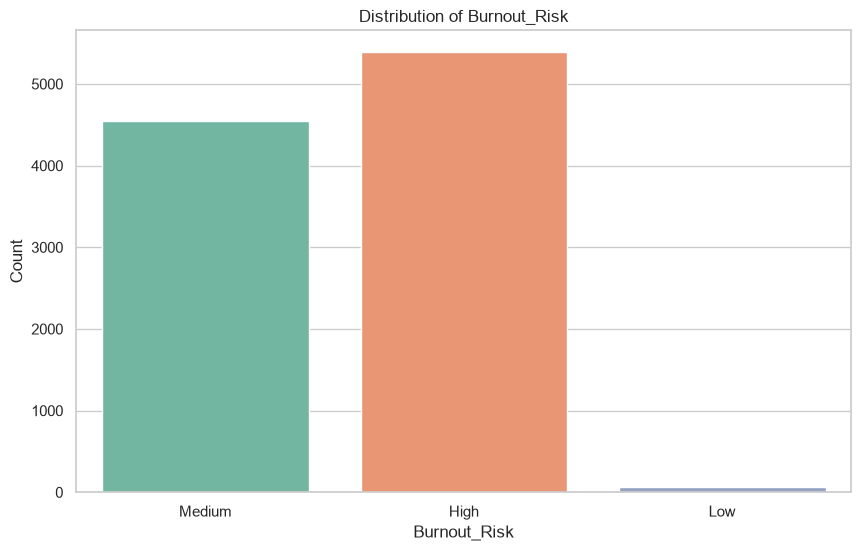

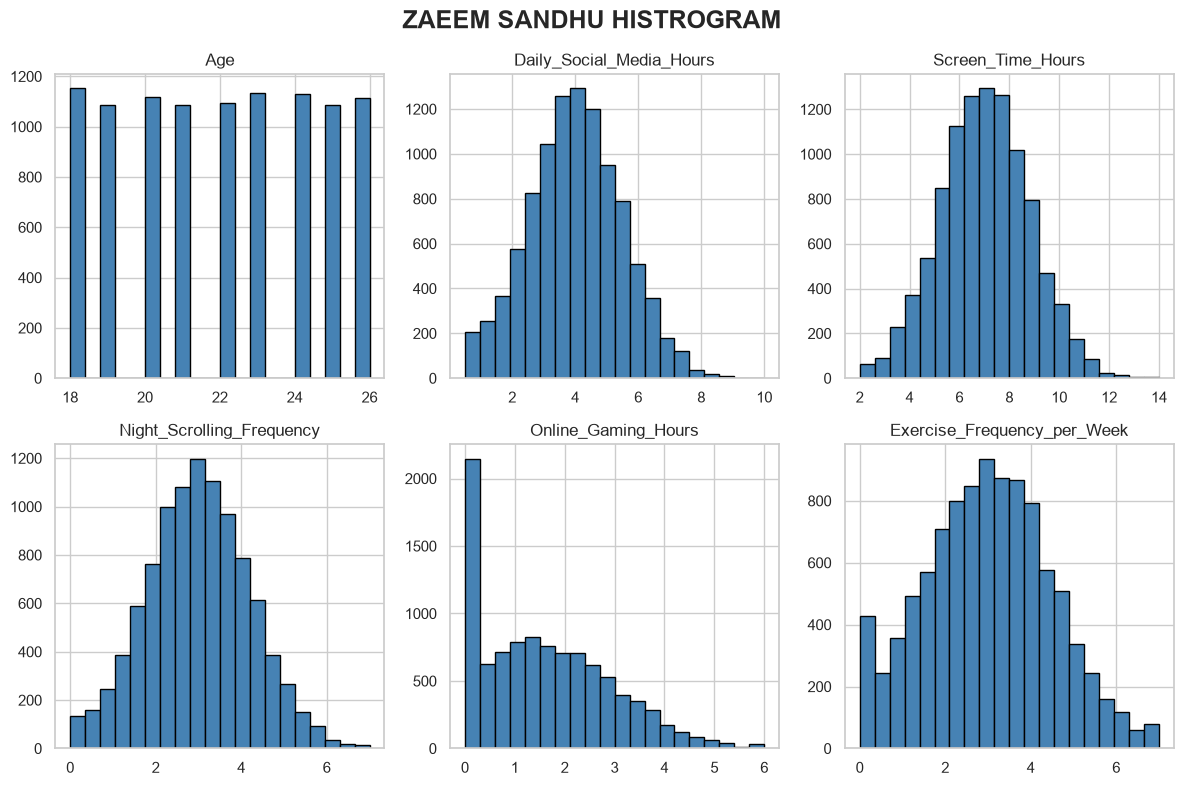

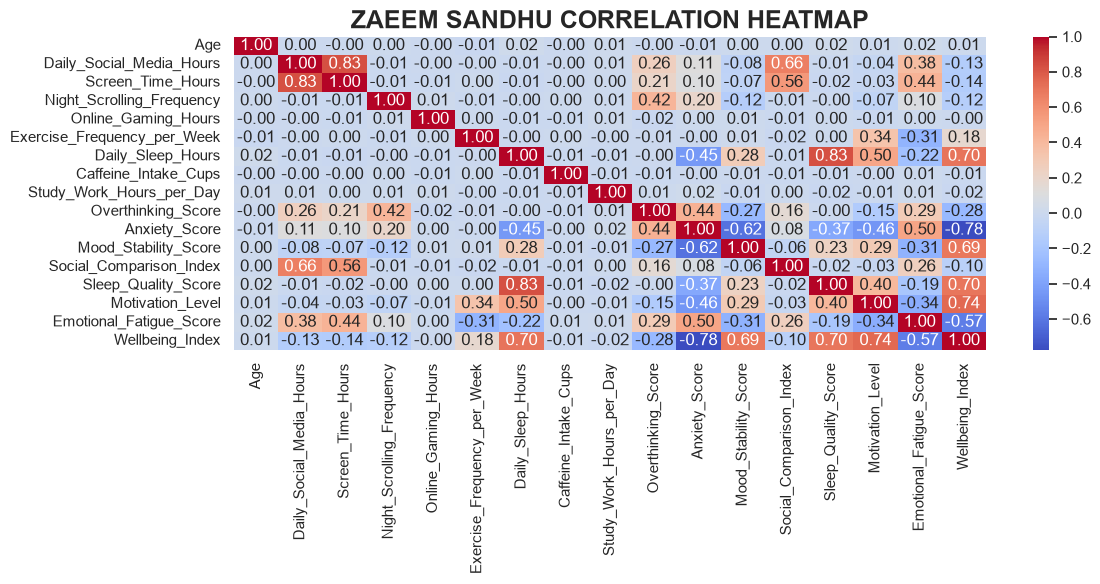

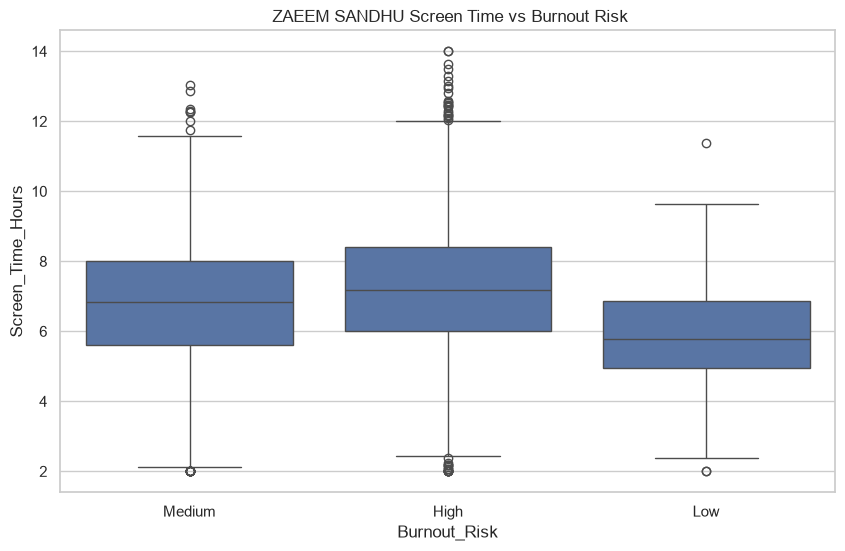

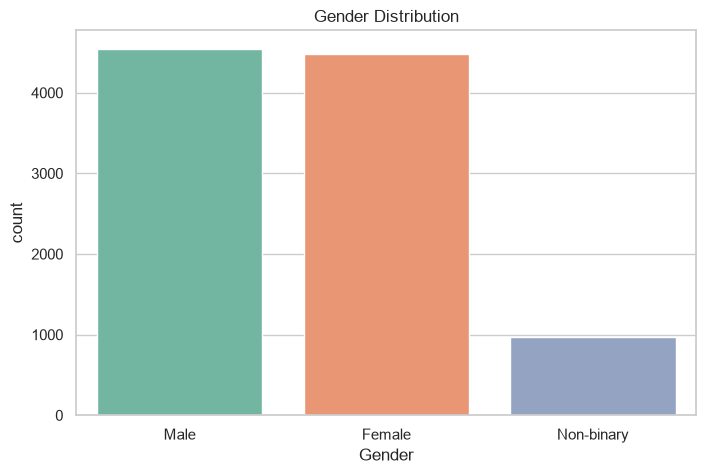

In [ ]:
# graph setting 
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# fixed target column
target_col = "Burnout_Risk"

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x=target_col, palette="Set2")
plt.title(f"Distribution of {target_col}")
plt.xlabel(target_col)
plt.ylabel("Count")
plt.show()

#numerical values of graph 
num_cols=df.select_dtypes(include=[np.number]).columns.tolist()


# "print("Before Removing:", num_cols)

# if target_col in num_cols:
#     num_cols.remove(target_col)
#     print("Removed Column:", target_col)
# else:
#     print("Koi column remove nahi hua.")

# print("After Removing:", num_cols)"
num_col = df.select_dtypes(include=[np.number]).columns.tolist()
if target_col in num_col:
    num_col.remove(target_col)
    

#for checking all dataset values graph seprately histrogram
clo_to_plot= num_col[:6] if len(num_col) >=6 else num_col 
if clo_to_plot:
     df[clo_to_plot].hist(bins=20,
                          figsize=(12, 8), 
                          layout=(2, 3), 
                          color='steelblue', 
                          edgecolor='black')
     plt.suptitle('ZAEEM SANDHU HISTROGRAM', 
                  fontsize=18,
                  fontweight='bold')
     plt.tight_layout()
     plt.show()

#relationship between datasetsnum_dfn
num_df = df.select_dtypes(include=[np.number])
if num_df.shape[1] > 1 :
    sns.heatmap(num_df.corr(), 
                annot=True,
                fmt=".2f", 
                cmap='coolwarm', 
                cbar=True)
    plt.title('ZAEEM SANDHU CORRELATION HEATMAP',
              fontsize=18,
              fontweight='bold')
    plt.tight_layout()
    plt.show()

# COMPERISON GRAPH 
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, 
            x="Burnout_Risk",
            y="Screen_Time_Hours")
plt.title(" ZAEEM SANDHU Screen Time vs Burnout Risk")
plt.show()

#DATASET GENDER DISTRIBUTION
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Gender",
              hue="Gender",
              palette="Set2",
              legend=False)
plt.title("Gender Distribution")
plt.show()



3 TRAINING AND TESTING CODE

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# 1 for removing unnecessary columns
drop_col = [c for c in df.columns
            if c not in num_col and c != target_col]
clean_df = df.drop(columns=drop_col).copy()

#2  converting data in numerical form
numeric_cols = df.select_dtypes(include=np.number).columns

for col in clean_df.select_dtypes(
    include=["object", "category"]).columns:
    le = LabelEncoder()
    clean_df[col] = le.fit_transform(clean_df[col].astype(str))


#3  for filling missing values
clean_df=clean_df.fillna(clean_df.mean(numeric_only=True))

#targetig coloumn
X = clean_df.drop(columns=[target_col])
Y = clean_df[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, Y,
    test_size=0.30,
    stratify=Y if Y.nunique() < 20 else None, 
    random_state=42)

#CONVERTING DATA IN NUMERICAL FORM
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Preprocessing Complete ")
print(f"Total Features: {X.shape[1]}")
print(f"Training Samples (70%): {X_train.shape[0]}")
print(f"Testing Samples (30%): {X_test.shape[0]}")

=== Preprocessing Complete ===
Total Features: 17
Training Samples (70%): 7000
Testing Samples (30%): 3000


C:\Users\bk\AppData\Local\Temp\ipykernel_10724\2183259123.py:12: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in clean_df.select_dtypes(


4- MODEL TRAINING AND EVALUATION 